# Импорты и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    RocCurveDisplay,
)

np.random.seed(42)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)

# 1. Загрузка и merge

In [2]:
simple = pd.read_csv("data/simple_features.csv")
semantic = pd.read_csv("data/semantic_features.csv").drop(columns=["ROBOT"])

df = simple.merge(semantic, on="ID", how="inner")

print("sessions:", df.shape[0])
print("ROBOT balance:")
print(df["ROBOT"].value_counts(normalize=True).round(3))

sessions: 67352
ROBOT balance:
ROBOT
0    0.8
1    0.2
Name: proportion, dtype: float64


# 2. Аудит: правила из статьи vs реальные данные

In [3]:
def audit_rule(df, mask, name):
    bot = (mask & (df["ROBOT"] == 1)).sum()
    human = (mask & (df["ROBOT"] == 0)).sum()
    total = bot + human
    purity = bot / total if total else 0.0
    print(f"{name:35s}  BOT={bot:6d}   HUMAN={human:6d}   purity(bot)={purity:.3f}")


print("\n--- Правила из статьи (behavioral indicators) ---")
audit_rule(df, df["IMAGES"] == 0, "IMAGES == 0")
audit_rule(df, df["SF_REFERRER"] == 0, "SF_REFERRER == 0")
audit_rule(df, df["HTTP_RESPONSE_4XX"] == 1.0, "HTTP_RESPONSE_4XX == 1.0")
audit_rule(df, df["HEAD_METHOD"] == 1.0, "HEAD_METHOD == 1.0")

print('\n--- UNASSIGNED как поведенческий прокси правила "нет статики" ---')
for thr in [0.01, 0.1, 0.25, 0.5, 0.7, 0.9, 1.0]:
    audit_rule(df, df["UNASSIGNED"] >= thr, f"UNASSIGNED >= {thr}")

# Пересечение с IMAGES == 0
images_zero = df["IMAGES"] == 0
high_unassigned = df["UNASSIGNED"] >= 0.9
print(f"\nIMAGES==0 И UNASSIGNED>=0.9: {(images_zero & high_unassigned).sum()}")
print(f"IMAGES==0 ИЛИ UNASSIGNED>=0.9: {(images_zero | high_unassigned).sum()}")


--- Правила из статьи (behavioral indicators) ---
IMAGES == 0                          BOT=  8073   HUMAN= 11040   purity(bot)=0.422
SF_REFERRER == 0                     BOT=  5170   HUMAN=  2802   purity(bot)=0.649
HTTP_RESPONSE_4XX == 1.0             BOT=   196   HUMAN=   243   purity(bot)=0.446
HEAD_METHOD == 1.0                   BOT=    91   HUMAN=    27   purity(bot)=0.771

--- UNASSIGNED как поведенческий прокси правила "нет статики" ---
UNASSIGNED >= 0.01                   BOT= 13140   HUMAN= 26959   purity(bot)=0.328
UNASSIGNED >= 0.1                    BOT= 13123   HUMAN=  9205   purity(bot)=0.588
UNASSIGNED >= 0.25                   BOT= 13110   HUMAN=  6205   purity(bot)=0.679
UNASSIGNED >= 0.5                    BOT= 13039   HUMAN=  4769   purity(bot)=0.732
UNASSIGNED >= 0.7                    BOT= 12950   HUMAN=  4020   purity(bot)=0.763
UNASSIGNED >= 0.9                    BOT= 12925   HUMAN=  3996   purity(bot)=0.764
UNASSIGNED >= 1.0                    BOT= 12924   HU

# 3. Наборы фич

In [ ]:
# 3.1 Прямые правила разметки + структурные эквиваленты - потенциальная утечка
LEAKY_DIRECT = [
    "IMAGES",
    "HTML_TO_IMAGE",
    "SF_REFERRER",
    "HTTP_RESPONSE_4XX",
    "HEAD_METHOD",
    "HTTP_RESPONSE_2XX",
    "HTTP_RESPONSE_3XX",
    "HTTP_RESPONSE_5XX",
    "GET_METHOD",
    "POST_METHOD",
    "OTHER_METHOD",
]

# 3.2 Безопасный набор - не участвовал в правилах
SAFE_FEATURES = [
    # интенсивность и время
    "NUMBER_OF_REQUESTS",
    "TOTAL_DURATION",
    "AVERAGE_TIME",
    "STANDARD_DEVIATION",
    "REPEATED_REQUESTS",
    # время суток / служебные
    "NIGHT",
    "UNASSIGNED",
    # структура обхода
    "TOTAL_HTML",
    "HTML_TO_CSS",
    "HTML_TO_JS",
    "WIDTH",
    "DEPTH",
    "STD_DEPTH",
    "CONSECUTIVE",
    "MAX_BARRAGE",
    "PENALTY",
    # прочее
    "DATA",
    "PPI",
    "SF_FILETYPE",
    # семантические
    "TOTAL_TOPICS",
    "UNIQUE_TOPICS",
    "PAGE_SIMILARITY",
    "PAGE_VARIANCE",
    "BOOLEAN_PAGE_VARIANCE",
]

# 3.3 Поведенческие прокси - не в правилах, но коррелируют с ними
BEHAVIORAL_PROXY = [
    "UNASSIGNED",
    "SF_FILETYPE",
    "HTML_TO_CSS",
    "HTML_TO_JS",
    "PENALTY",
]
SAFE_STRICT_FEATURES = [f for f in SAFE_FEATURES if f not in BEHAVIORAL_PROXY]


# 3.4 Feature engineering - только безопасные производные
eps = 1e-9
df["cv_time"] = df["STANDARD_DEVIATION"] / (df["AVERAGE_TIME"] + eps)
df["request_rate"] = df["NUMBER_OF_REQUESTS"] / (df["TOTAL_DURATION"] + eps)
df["html_ratio"] = df["TOTAL_HTML"] / (df["NUMBER_OF_REQUESTS"] + eps)
df["repeated_ratio"] = df["REPEATED_REQUESTS"] / (df["NUMBER_OF_REQUESTS"] + eps)
df["topics_per_req"] = df["TOTAL_TOPICS"] / (df["NUMBER_OF_REQUESTS"] + eps)

DERIVED = ["cv_time", "request_rate", "html_ratio", "repeated_ratio", "topics_per_req"]
SAFE_FEATURES += DERIVED
SAFE_STRICT_FEATURES += DERIVED


# 3.5 V5 - только поведение: время, интенсивность, структура.
#     Убираем ВСЕ типы контента (DATA, PPI, TOTAL_HTML, html_ratio,
#     UNASSIGNED, HTML_TO_CSS/JS, SF_FILETYPE) и служебные штрафы.
V5_FEATURES = [
    # время и интенсивность
    "NUMBER_OF_REQUESTS",
    "TOTAL_DURATION",
    "AVERAGE_TIME",
    "STANDARD_DEVIATION",
    "REPEATED_REQUESTS",
    "cv_time",
    "request_rate",
    "repeated_ratio",
    "MAX_BARRAGE",
    "CONSECUTIVE",
    # структура обхода
    "WIDTH",
    "DEPTH",
    "STD_DEPTH",
    # семантика
    "TOTAL_TOPICS",
    "UNIQUE_TOPICS",
    "PAGE_SIMILARITY",
    "PAGE_VARIANCE",
]

print(
    f"\nLEAKY_DIRECT: {len(LEAKY_DIRECT)} | "
    f"SAFE: {len(SAFE_FEATURES)} | "
    f"SAFE_STRICT: {len(SAFE_STRICT_FEATURES)} | "
    f"V5: {len(V5_FEATURES)}"
)


LEAKY_DIRECT: 11 | SAFE: 29 | SAFE_STRICT: 24 | V5: 17


# 4. Train/test split

In [5]:
y = df["ROBOT"]
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.25,
    stratify=y,
    random_state=42,
)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]


def build_model():
    return RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42,
    )

# 5. Модели V1–V5

In [6]:
results = []


def evaluate(name, feature_list, model=None):
    X_tr = df.loc[idx_train, feature_list].fillna(0)
    X_te = df.loc[idx_test, feature_list].fillna(0)
    m = model if model is not None else build_model()
    m.fit(X_tr, y_train)
    proba = m.predict_proba(X_te)[:, 1]
    auc = roc_auc_score(y_test, proba)
    results.append({"model": name, "n_features": len(feature_list), "roc_auc": auc})
    print(f"{name:28s}  ROC-AUC = {auc:.4f}")
    return m, proba


# V1: все фичи (safe + leaky)
print("\n--- Модели ---")
m1, proba1 = evaluate("V1: all features", SAFE_FEATURES + LEAKY_DIRECT)

# V2: без прямых правил (LogReg baseline + RF)
X2_tr = df.loc[idx_train, SAFE_FEATURES].fillna(0)
X2_te = df.loc[idx_test, SAFE_FEATURES].fillna(0)

logreg = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]
).fit(X2_tr, y_train)
proba_lr = logreg.predict_proba(X2_te)[:, 1]
auc_lr = roc_auc_score(y_test, proba_lr)
results.append(
    {"model": "V2: LogReg safe", "n_features": len(SAFE_FEATURES), "roc_auc": auc_lr}
)
print(f'{"V2: LogReg safe":28s}  ROC-AUC = {auc_lr:.4f}')

m2, proba2 = evaluate("V2: RF safe", SAFE_FEATURES)

# V3: без поведенческих прокси
m3, proba3 = evaluate("V3: RF strict", SAFE_STRICT_FEATURES)

# V4: strict без UNASSIGNED
SAFE_NO_UNASSIGNED = [f for f in SAFE_STRICT_FEATURES if f != "UNASSIGNED"]
m4, proba4 = evaluate("V4: RF без UNASSIGNED", SAFE_NO_UNASSIGNED)

# V5: только поведение (главный результат)
m5, proba5 = evaluate("V5: RF поведение", V5_FEATURES)

print("\n--- Сводка ---")
print(pd.DataFrame(results).round(4).to_string(index=False))


--- Модели ---
V1: all features              ROC-AUC = 0.9957
V2: LogReg safe               ROC-AUC = 0.9818
V2: RF safe                   ROC-AUC = 0.9957
V3: RF strict                 ROC-AUC = 0.9897
V4: RF без UNASSIGNED         ROC-AUC = 0.9897
V5: RF поведение              ROC-AUC = 0.9704

--- Сводка ---
                model  n_features  roc_auc
     V1: all features          40   0.9957
      V2: LogReg safe          29   0.9818
          V2: RF safe          29   0.9957
        V3: RF strict          24   0.9897
V4: RF без UNASSIGNED          24   0.9897
     V5: RF поведение          17   0.9704


# 6. Leave-one-feature-out

In [8]:
print("\n--- Leave-one-feature-out (V4) ---")
base_auc = roc_auc_score(y_test, proba4)
print(f"Baseline (V4): {base_auc:.4f}")

lofo_rows = []
for f in perm4_df["feature"].head(8):
    feats = [x for x in SAFE_NO_UNASSIGNED if x != f]
    m = build_model().fit(df.loc[idx_train, feats].fillna(0), y_train)
    auc = roc_auc_score(
        y_test, m.predict_proba(df.loc[idx_test, feats].fillna(0))[:, 1]
    )
    lofo_rows.append({"feature": f, "auc_without": auc, "delta": auc - base_auc})

lofo_df = pd.DataFrame(lofo_rows).sort_values("delta")
print(lofo_df.round(4).to_string(index=False))


--- Leave-one-feature-out (V4) ---
Baseline (V4): 0.9897
     feature  auc_without   delta
        DATA       0.9834 -0.0063
         PPI       0.9882 -0.0015
  TOTAL_HTML       0.9891 -0.0006
  html_ratio       0.9893 -0.0004
       DEPTH       0.9895 -0.0002
TOTAL_TOPICS       0.9898  0.0001
 MAX_BARRAGE       0.9898  0.0001
     cv_time       0.9900  0.0003


# 7. Корреляция топ-фич с UNASSIGNED

In [ ]:
cols_check = [
    "DATA",
    "PPI",
    "TOTAL_HTML",
    "html_ratio",
    "DEPTH",
    "STD_DEPTH",
    "cv_time",
    "MAX_BARRAGE",
    "UNASSIGNED",
]
corr = (
    df[cols_check]
    .corr()["UNASSIGNED"]
    .drop("UNASSIGNED")
    .sort_values(key=np.abs, ascending=False)
)
print("\nКорреляция с UNASSIGNED:")
print(corr.round(3))
# |corr| < 0.3 - независимый сигнал (DATA, PPI)
# 0.3–0.7 - связан, но не эквивалентен (TOTAL_HTML, html_ratio,
#          cv_time, MAX_BARRAGE, STD_DEPTH, DEPTH - поведенческие)


Корреляция с UNASSIGNED:
DEPTH         -0.559
STD_DEPTH     -0.477
MAX_BARRAGE   -0.455
cv_time       -0.432
TOTAL_HTML     0.412
html_ratio     0.387
DATA           0.053
PPI            0.045
Name: UNASSIGNED, dtype: float64


# 8. Кросс-валидация - стабильность оценок

In [10]:
print("\n--- 5-fold CV ---")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, feats in [
    ("V2 RF safe", SAFE_FEATURES),
    ("V4 RF strict", SAFE_NO_UNASSIGNED),
    ("V5 RF behavior", V5_FEATURES),
]:
    X = df[feats].fillna(0)
    scores = cross_val_score(build_model(), X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name:18s}  {scores.mean():.4f} ± {scores.std():.4f}")


--- 5-fold CV ---
V2 RF safe          0.9951 ± 0.0002
V4 RF strict        0.9888 ± 0.0002
V5 RF behavior      0.9692 ± 0.0014


# 9. Визуализация

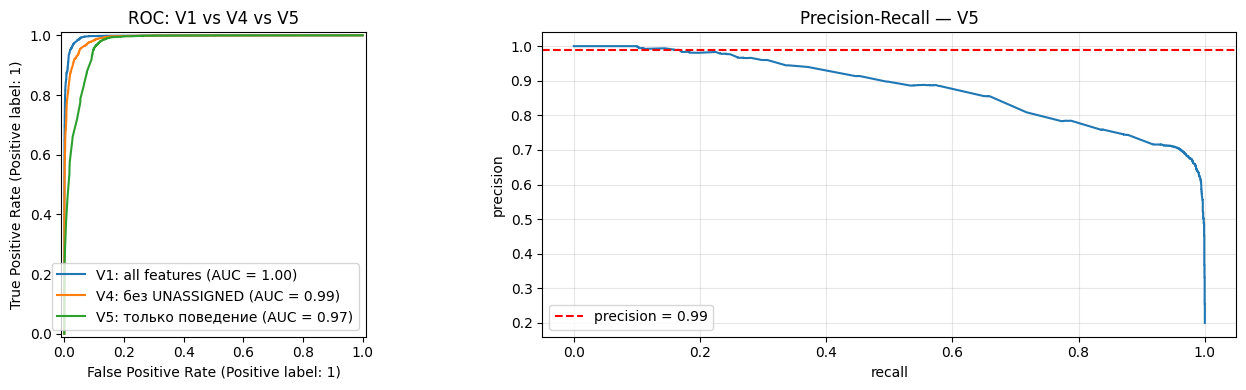

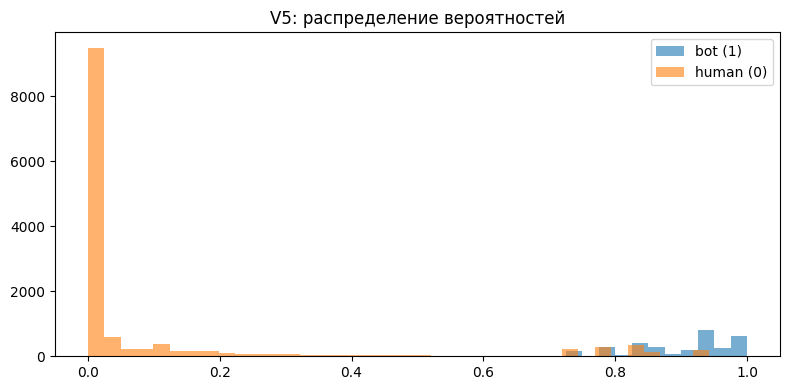

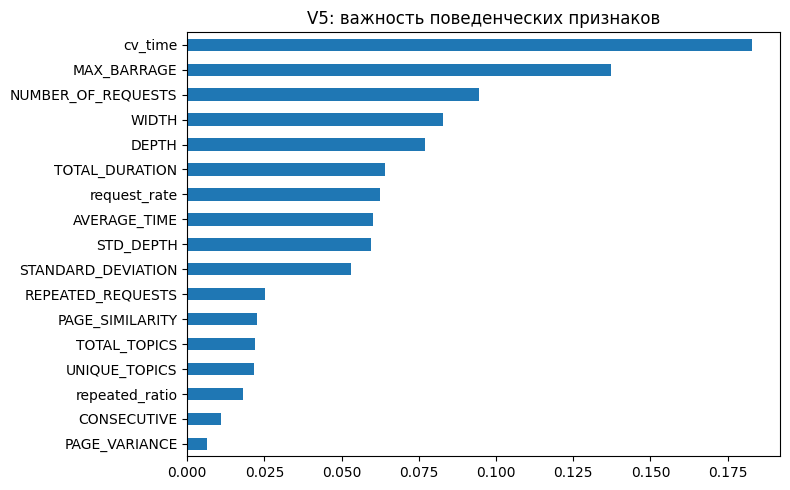

In [ ]:
prec, rec, thr = precision_recall_curve(y_test, proba5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

RocCurveDisplay.from_predictions(y_test, proba1, ax=axes[0], name="V1: all features")
RocCurveDisplay.from_predictions(y_test, proba4, ax=axes[0], name="V4: без UNASSIGNED")
RocCurveDisplay.from_predictions(
    y_test, proba5, ax=axes[0], name="V5: только поведение"
)
axes[0].set_title("ROC: V1 vs V4 vs V5")

axes[1].plot(rec, prec)
axes[1].axhline(0.99, color="red", linestyle="--", label="precision = 0.99")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-Recall - V5")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Распределение вероятностей V5
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(proba5[y_test == 1], bins=40, alpha=0.6, label="bot (1)")
ax.hist(proba5[y_test == 0], bins=40, alpha=0.6, label="human (0)")
ax.set_title("V5: распределение вероятностей")
ax.legend()
plt.tight_layout()
plt.show()

# Какие поведенческие признаки работают
imp5 = pd.Series(m5.feature_importances_, index=V5_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
imp5.plot(kind="barh", ax=ax)
ax.set_title("V5: важность поведенческих признаков")
plt.tight_layout()
plt.show()

# 10. Подбор порога автобана под precision ≥ 0.99

In [12]:
print("--- Поиск порога автобана (precision ≥ 0.99) ---")
print(f'{"threshold":>10}  {"TP":>5}  {"FP":>4}  {"precision":>10}  {"recall":>8}')

best_thr = None
for thr_t in np.arange(0.90, 0.999, 0.005):
    mask = proba5 >= thr_t
    tp = ((mask) & (y_test == 1)).sum()
    fp = ((mask) & (y_test == 0)).sum()
    if tp == 0:
        continue
    p = tp / (tp + fp)
    r = tp / (y_test == 1).sum()
    flag = " ←" if p >= 0.99 and best_thr is None else ""
    if p >= 0.99 and best_thr is None:
        best_thr = thr_t
        print(f"{thr_t:>10.3f}  {tp:>5d}  {fp:>4d}  {p:>10.3f}  {r:>8.3f}{flag}")
        break

print(f"\nРекомендуемый порог автобана: {best_thr:.3f}")

# Сколько ботов ловим автобаном при этом пороге, сколько уходит в review
mask_ban = proba5 >= best_thr
mask_review = (proba5 >= 0.20) & (proba5 < best_thr)

n_bots = (y_test == 1).sum()
print(
    f"\nАвтобан:  TP={((mask_ban) & (y_test==1)).sum():4d}  FP={((mask_ban) & (y_test==0)).sum():4d}  "
    f"recall={((mask_ban) & (y_test==1)).sum()/n_bots:.1%}"
)
print(
    f"Review:   ботов={((mask_review) & (y_test==1)).sum():4d}  людей={((mask_review) & (y_test==0)).sum():4d}"
)
print(f"Пропуск:  ботов={((~mask_ban) & (~mask_review) & (y_test==1)).sum():4d}")

--- Поиск порога автобана (precision ≥ 0.99) ---
 threshold     TP    FP   precision    recall
     0.985    460     3       0.994     0.136 ←

Рекомендуемый порог автобана: 0.985

Автобан:  TP= 460  FP=   3  recall=13.6%
Review:   ботов=2883  людей=2003
Пропуск:  ботов=  30
